In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [8]:
pip install odfpy openpyxl

     ---------------------------------------- 0.0/717.0 kB ? eta -:--:--
     --------------------------- --------- 524.3/717.0 kB 16.4 MB/s eta 0:00:01
     ---------------------------------------- 717.0/717.0 kB 3.6 MB/s  0:00:00
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for odfpy: filename=odfpy-1.4.1-py2.py3-none-any.whl size=137564 sha256=d7ca8b2d1b3bddd45d671335e22556f039f098e0088d6e7b1a7c3859b905b7d1
  Stored in directory: c:\users\nagar\appdata\local\pip\cache\wheels\d6\1d\c8\8c29be1d73ca42d15977c75193d9f39a98499413c2838ac54c
Successfully built odfpy

   ---------------------------------------- 0/3 [odfpy]
   ---------------------------------------- 0/3 [odfpy]
   ---------------

In [27]:
PROJECT_ROOT = Path.cwd().parents[1]

DATA_ROOT = PROJECT_ROOT / "data" / "external" / "swell"

print("Project directory:", PROJECT_ROOT)
print("SWELL directory:", DATA_ROOT)
print("Directory exists:", DATA_ROOT.exists())

Project directory: d:\NeuroSync
SWELL directory: d:\NeuroSync\data\external\swell
Directory exists: True


In [ ]:
# List all files in the SWELL dataset directory
all_files = [
    file for file in DATA_ROOT.rglob("*")
    if file.is_file()
]

print("Total files:", len(all_files))

for file in all_files:
    print(file.name)

Total files: 5
A - Computer interaction features (Ulog - All Features per minute).xlsx
Behavioral-features - per minute.ods
Questionnaire Blok Results_final - performance added.ods
Questionnaire Start Results_final_noBankdata.ods
SWELL-KW - overview available data.ods


In [29]:
# Identify behavioral feature files
behavioral_files = [
    file for file in all_files
    if "behavioral-features" in file.name.lower()
]

computer_files = [
    file for file in all_files
    if "computer interaction features" in file.name.lower()
]

questionnaire_files = [
    file for file in all_files
    if "questionnaire" in file.name.lower()
]

print("Behavioral files:")
for file in behavioral_files:
    print(file.name)

print("\nComputer interaction files:")
for file in computer_files:
    print(file.name)

print("\nQuestionnaire files:")
for file in questionnaire_files:
    print(file.name)

Behavioral files:
Behavioral-features - per minute.ods

Computer interaction files:
A - Computer interaction features (Ulog - All Features per minute).xlsx

Questionnaire files:
Questionnaire Blok Results_final - performance added.ods
Questionnaire Start Results_final_noBankdata.ods


### Load the behavioral feature spreadsheet

In [30]:
behavioral_path = DATA_ROOT / "Behavioral-features - per minute.ods"

behavioral_excel = pd.ExcelFile(
    behavioral_path,
    engine="odf"
)

print("Available sheets:")
print(behavioral_excel.sheet_names)

Available sheets:
['SWELLdata', 'Features and interest', 'Features and interest ordered', 'Notes on the data']


In [31]:
behavioral_df = pd.read_excel(
    behavioral_path,
    sheet_name=0,
    engine="odf"
)

print("Dataset shape:", behavioral_df.shape)

display(behavioral_df.head())

Dataset shape: (3139, 172)


,PP,Blok,Condition,timestamp,Valence_rc,Arousal_rc,Dominance,Stress,MentalEffort,MentalDemand,...,WristLeft_HandLeftPlaneYZAxisZstdv,ShoulderRight_ElbowRightPlaneZXAxisXstdv,ShoulderRight_ElbowRightPlaneXYAxisYstdv,ShoulderRight_ElbowRightPlaneYZAxisZstdv,ElbowRight_WristRightPlaneZXAxisXstdv,ElbowRight_WristRightPlaneXYAxisYstdv,ElbowRight_WristRightPlaneYZAxisZstdv,WristRight_HandRightPlaneZXAxisXstdv,WristRight_HandRightPlaneXYAxisYstdv,WristRight_HandRightKinectZAxisstdv
0,PP1,1,R,20120918T131600000,NaN,NaN,NaN,NaN,NaN,NaN,...,166.872086,22.946337,5.605230,13.237048,30.932939,102.460262,8.444481,54.436879,75.886750,155.734343
1,PP1,1,R,20120918T131700000,NaN,NaN,NaN,NaN,NaN,NaN,...,58.237714,7.194860,2.468881,3.886001,2.000359,3.431337,1.160298,4.579341,2.868843,171.486911
2,PP1,1,R,20120918T131800000,NaN,NaN,NaN,NaN,NaN,NaN,...,64.548824,14.726365,2.953021,9.185623,13.379140,48.162012,30.508877,23.013755,30.629061,149.748809
3,PP1,1,R,20120918T131900000,NaN,NaN,NaN,NaN,NaN,NaN,...,38.209895,2.542686,1.564318,2.453674,4.796273,8.223865,1.114906,3.854074,4.048611,173.149430
4,PP1,1,R,20120918T132000000,NaN,NaN,NaN,NaN,NaN,NaN,...,80.171422,9.905241,20.342488,5.552234,7.198096,22.942488,46.386278,17.514534,29.702675,165.368301


### Load computer-interaction features

In [32]:
computer_path = DATA_ROOT / (
    "A - Computer interaction features "
    "(Ulog - All Features per minute).xlsx"
)

computer_excel = pd.ExcelFile(computer_path)

print("Available sheets:")
print(computer_excel.sheet_names)

Available sheets:
['Sheet1', 'Sheet2', 'Sheet3']


In [33]:
computer_sheets = pd.read_excel(
    computer_path,
    sheet_name=None
)

for sheet_name, data in computer_sheets.items():

    print("\nSheet:", sheet_name)
    print("Shape:", data.shape)

    display(data.head())


Sheet: Sheet1
Shape: (3139, 22)


,PP,Blok,Condition,timestamp,SnMouseAct,SnLeftClicked,SnRightClicked,SnDoubleClicked,SnWheel,SnDragged,...,SnChars,SnSpecialKeys,SnDirectionKeys,SnErrorKeys,SnShortcutKeys,SnSpaces,SnAppChange,SnTabfocusChange,Unnamed: 20,Unnamed: 21
0,PP1,1,R,20120918T131600000,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,NaN,NaN
1,PP1,1,R,20120918T131700000,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,NaN,NaN
2,PP1,1,R,20120918T131800000,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,NaN,NaN
3,PP1,1,R,20120918T131900000,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,NaN,NaN
4,PP1,1,R,20120918T132000000,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,NaN,NaN



Sheet: Sheet2
Shape: (82, 12)


,PP,Blok,Condition,date,startBlock,startWork,endBlock,Tmovie,Ttask,Unnamed: 9,Unnamed: 10,LEGEND:
0,NaN,NaN,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,SP,1.0,N,2012-09-13,12:47:00,12:56:00,13:29:00,00:09:00,00:33:00,NaN,NaN,uLog crashed
2,SP,2.0,I,2012-09-13,15:02:00,15:10:00,15:32:00,00:08:00,00:22:00,NaN,NaN,solved with Mayas bugfix
3,SP,3.0,T,2012-09-13,14:05:00,14:13:00,14:46:00,00:08:00,00:33:00,NaN,NaN,solved new version Counts
4,MP,1.0,N,2012-09-14,14:25:00,14:35:00,15:08:00,00:10:00,00:33:00,NaN,NaN,Invalid stuff in uLog



Sheet: Sheet3
Shape: (3140, 21)


,PP,Blok,Condition,timestamp,SnMouseAct,SnLeftClicked,SnRightClicked,SnDoubleClicked,SnWheel,SnDragged,...,SnMouseDistance.1,SnKeyStrokes,SnChars,SnSpecialKeys,SnDirectionKeys,SnErrorKeys,SnShortcutKeys,SnSpaces,SnAppChange,SnTabfocusChange
0,PP1,1,R,20120918T131600000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,PP1,1,R,20120918T131700000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,PP1,1,R,20120918T131800000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,PP1,1,R,20120918T131900000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,PP1,1,R,20120918T132000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [34]:
behavioral_df.columns.tolist()

['PP',
 'Blok',
 'Condition',
 'timestamp',
 'Valence_rc',
 'Arousal_rc',
 'Dominance',
 'Stress',
 'MentalEffort',
 'MentalDemand',
 'PhysicalDemand',
 'TemporalDemand',
 'Effort',
 'Performance_rc',
 'Frustration',
 'NasaTLX',
 'HR',
 'RMSSD',
 'SCL',
 'Squality',
 'Sneutral',
 'Shappy',
 'Ssad',
 'Sangry',
 'Ssurprised',
 'Sscared',
 'Sdisgusted',
 'Svalence',
 'SyHeadOrientation',
 'SxHeadOrientation',
 'SzHeadOrientation',
 'SmouthOpen',
 'SleftEyeClosed',
 'SrightEyeClosed',
 'SleftEyebrowLowered',
 'SleftEyebrowRaised',
 'SrightEyebrowLowered',
 'SrightEyebrowRaised',
 'SgazeDirectionForward',
 'SgazeDirectionLeft',
 'SgazeDirectionRight',
 'SAu01_InnerBrowRaiser',
 'SAu02_OuterBrowRaiser',
 'SAu04_BrowLowerer',
 'SAu05_UpperLidRaiser',
 'SAu06_CheekRaiser',
 'SAu07_LidTightener',
 'SAu09_NoseWrinkler',
 'SAu10_UpperLipRaiser',
 'SAu12_LipCornerPuller',
 'SAu14_Dimpler',
 'SAu15_LipCornerDepressor',
 'SAu17_ChinRaiser',
 'SAu20_LipStretcher',
 'SAu23_LipTightener',
 'SAu24_LipPr

In [36]:
behavioral_df.dtypes

PP                                           str
Blok                                       int64
Condition                                    str
timestamp                                    str
Valence_rc                               float64
                                          ...   
ElbowRight_WristRightPlaneXYAxisYstdv    float64
ElbowRight_WristRightPlaneYZAxisZstdv    float64
WristRight_HandRightPlaneZXAxisXstdv     float64
WristRight_HandRightPlaneXYAxisYstdv     float64
WristRight_HandRightKinectZAxisstdv      float64
Length: 172, dtype: object

In [37]:
for sheet_name, df in computer_sheets.items():

    print("\n", "=" * 60)
    print("SHEET:", sheet_name)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nShape:")
    print(df.shape)


SHEET: Sheet1

Columns:
['PP', 'Blok', 'Condition', 'timestamp', 'SnMouseAct', 'SnLeftClicked', 'SnRightClicked', 'SnDoubleClicked', 'SnWheel', 'SnDragged', 'SnMouseDistance', 'SnKeyStrokes', 'SnChars', 'SnSpecialKeys', 'SnDirectionKeys', 'SnErrorKeys', 'SnShortcutKeys', 'SnSpaces', 'SnAppChange', 'SnTabfocusChange', 'Unnamed: 20', 'Unnamed: 21']

Data types:
PP                      str
Blok                  int64
Condition               str
timestamp               str
SnMouseAct            int64
SnLeftClicked         int64
SnRightClicked        int64
SnDoubleClicked       int64
SnWheel               int64
SnDragged             int64
SnMouseDistance     float64
SnKeyStrokes          int64
SnChars               int64
SnSpecialKeys         int64
SnDirectionKeys       int64
SnErrorKeys           int64
SnShortcutKeys        int64
SnSpaces              int64
SnAppChange           int64
SnTabfocusChange      int64
Unnamed: 20         float64
Unnamed: 21             str
dtype: object

Shape:

### Load the questionnaire spreadsheets

In [38]:
questionnaire_start_path = DATA_ROOT / (
    "Questionnaire Start Results_final_noBankdata.ods"
)

questionnaire_block_path = DATA_ROOT / (
    "Questionnaire Blok Results_final - performance added.ods"
)

questionnaire_start = pd.read_excel(
    questionnaire_start_path,
    engine="odf"
)

questionnaire_block = pd.read_excel(
    questionnaire_block_path,
    engine="odf"
)

print("START QUESTIONNAIRE:", questionnaire_start.shape)
display(questionnaire_start.head())

print("\nBLOCK QUESTIONNAIRE:", questionnaire_block.shape)
display(questionnaire_block.head())

START QUESTIONNAIRE: (55, 20)


,PP,Unnamed: 1,Age,Gender,Occupation,Unnamed: 5,Dominant hand,Glasses,How long ago did you…,smoke,coffee,alcohol,physical,stress,Unnamed: 14,heart disease,medicine,Unnamed: 17,Unnamed: 18,Internal control index
0,PP1,NaN,27.0,m,student,NaN,right,no,NaN,6,6,6.0,6.0,6.0,NaN,no,no,NaN,NaN,2.93
1,PP2,NaN,25.0,m,student,NaN,right,no,NaN,6,6,6.0,4.0,5.0,NaN,no,no,NaN,NaN,4.25
2,PP3,NaN,24.0,m,student,NaN,right,no,NaN,6,6,6.0,6.0,6.0,NaN,no,no,NaN,NaN,3.61
3,PP4,NaN,24.0,m,student,NaN,right,no,NaN,6,6,6.0,2.0,6.0,NaN,no,no,NaN,NaN,3.61
4,PP5,NaN,24.0,f,student,NaN,right,no,NaN,6,6,6.0,6.0,6.0,NaN,no,no,NaN,NaN,3.71



BLOCK QUESTIONNAIRE: (89, 47)


,PP,Blok,Condition,Unnamed: 3,Valence,Valnce (recoded),Arousal,Arousal (recoded),Dominance,Unnamed: 9,...,DifficultReport2,DifficultPresentation,Average of done,Unnamed: 40,InterestTopic1,InterestTopic2,Average over done,Unnamed: 44,Unnamed: 45,Comments
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,SP,1.0,N,NaN,6.0,3.0,3.0,6.0,5.0,NaN,...,2,0,NaN,NaN,3,3,NaN,NaN,NaN,Unclear expectations regarding reports.
2,SP,2.0,I,NaN,4.0,5.0,5.0,4.0,7.0,NaN,...,4,1,NaN,NaN,1,5,NaN,NaN,NaN,NaN
3,SP,3.0,T,NaN,3.0,6.0,3.0,6.0,3.0,NaN,...,5,1,NaN,NaN,1,0,NaN,NaN,NaN,NaN
4,MP,1.0,N,NaN,2.0,7.0,4.0,5.0,5.0,NaN,...,3,1,NaN,NaN,4,5,NaN,NaN,NaN,NaN


### Analyze missing values

In [39]:
def analyze_missing_values(df, dataset_name):

    missing = pd.DataFrame({
        "Missing Count": df.isnull().sum(),
        "Missing Percentage": (
            df.isnull().mean() * 100
        )
    })

    missing = missing.sort_values(
        "Missing Percentage",
        ascending=False
    )

    print("\nDataset:", dataset_name)
    display(missing)


analyze_missing_values(
    behavioral_df,
    "Behavioral Features"
)

for sheet_name, df in computer_sheets.items():

    analyze_missing_values(
        df,
        f"Computer Interaction - {sheet_name}"
    )

analyze_missing_values(
    questionnaire_start,
    "Start Questionnaire"
)

analyze_missing_values(
    questionnaire_block,
    "Block Questionnaire"
)


Dataset: Behavioral Features


,Missing Count,Missing Percentage
HR,1649,52.532654
RMSSD,1649,52.532654
ShoulderCenter_ShoulderLeftPlaneZXAxisXstdv,616,19.624084
ShoulderLeft_ElbowLeftPlaneYZAxisZstdv,581,18.509079
SCL,561,17.871934
...,...,...
PP,0,0.000000
timestamp,0,0.000000
Condition,0,0.000000
ErrorKeyRatio,0,0.000000



Dataset: Computer Interaction - Sheet1


,Missing Count,Missing Percentage
Unnamed: 20,3139,100.000000
Unnamed: 21,3137,99.936285
SnMouseDistance,2,0.063715
Condition,0,0.000000
PP,0,0.000000
Blok,0,0.000000
SnLeftClicked,0,0.000000
SnMouseAct,0,0.000000
timestamp,0,0.000000
SnRightClicked,0,0.000000



Dataset: Computer Interaction - Sheet2


,Missing Count,Missing Percentage
Unnamed: 9,82,100.000000
LEGEND:,76,92.682927
Unnamed: 10,59,71.951220
PP,1,1.219512
date,1,1.219512
Condition,1,1.219512
Blok,1,1.219512
startBlock,1,1.219512
Tmovie,1,1.219512
endBlock,1,1.219512


... (2 outputs left out)


Dataset: Start Questionnaire


,Missing Count,Missing Percentage
Unnamed: 1,55,100.000000
Unnamed: 17,55,100.000000
How long ago did you…,55,100.000000
Unnamed: 5,55,100.000000
Unnamed: 14,55,100.000000
Unnamed: 18,53,96.363636
PP,30,54.545455
Age,30,54.545455
Gender,30,54.545455
Glasses,30,54.545455



Dataset: Block Questionnaire


,Missing Count,Missing Percentage
Unnamed: 3,89,100.000000
Task Load…,89,100.000000
Unnamed: 9,89,100.000000
Unnamed: 32,89,100.000000
Unnamed: 35,89,100.000000
Unnamed: 45,89,100.000000
Weights…,89,100.000000
Unnamed: 40,86,96.629213
Unnamed: 44,81,91.011236
Comments,30,33.707865


### Summaries

In [40]:
print("BEHAVIORAL STATISTICS")

display(
    behavioral_df.describe(
        include="all"
    ).T
)

BEHAVIORAL STATISTICS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PP,3139,25,PP7,130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Blok,3139.0,NaN,NaN,NaN,1.936923,0.826873,1.0,1.0,2.0,3.0,3.0
Condition,3139,4,N,1028,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,3139,3139,20120918T131600000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Valence_rc,2688.0,NaN,NaN,NaN,6.259301,1.728531,2.0,5.0,7.0,7.0,9.0
...,...,...,...,...,...,...,...,...,...,...,...
ElbowRight_WristRightPlaneXYAxisYstdv,2734.0,NaN,NaN,NaN,78.556022,46.88005,0.226613,37.807103,84.253276,117.872324,170.815729
ElbowRight_WristRightPlaneYZAxisZstdv,2736.0,NaN,NaN,NaN,48.410653,41.344857,0.430113,12.609046,35.845708,79.340451,172.52407
WristRight_HandRightPlaneZXAxisXstdv,2735.0,NaN,NaN,NaN,53.805654,32.785143,0.109214,28.150308,48.041465,75.153577,164.851778
WristRight_HandRightPlaneXYAxisYstdv,2734.0,NaN,NaN,NaN,86.226423,40.281127,0.008504,57.943611,91.696256,116.527541,170.120333


In [41]:
for sheet_name, df in computer_sheets.items():

    print("\nSheet:", sheet_name)

    display(
        df.describe(include="all").T
    )


Sheet: Sheet1


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PP,3139,25,PP7,130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Blok,3139.0,NaN,NaN,NaN,1.936923,0.826873,1.0,1.0,2.0,3.0,3.0
Condition,3139,4,N,1028,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,3139,3139,20120918T131600000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SnMouseAct,3139.0,NaN,NaN,NaN,23.244982,98.539873,0.0,0.0,10.0,22.0,999.0
SnLeftClicked,3139.0,NaN,NaN,NaN,15.855368,98.418191,0.0,0.0,4.0,10.0,999.0
SnRightClicked,3139.0,NaN,NaN,NaN,10.066582,98.783933,0.0,0.0,0.0,0.0,999.0
SnDoubleClicked,3139.0,NaN,NaN,NaN,10.231921,98.773213,0.0,0.0,0.0,0.0,999.0
SnWheel,3139.0,NaN,NaN,NaN,13.242752,98.652794,0.0,0.0,1.0,5.0,999.0
SnDragged,3139.0,NaN,NaN,NaN,11.572794,98.67008,0.0,0.0,1.0,2.0,999.0



Sheet: Sheet2


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
PP,81,27,SP,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Blok,81.0,NaN,NaN,NaN,2.0,1.0,1.0,2.0,3.0,3.0,0.821584
Condition,81,3,N,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,81,NaN,NaN,NaN,2012-10-09 23:06:40,2012-09-13 00:00:00,2012-09-26 00:00:00,2012-10-09 00:00:00,2012-10-19 00:00:00,2012-11-07 00:00:00,NaN
startBlock,81,72,14:25:00,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
startWork,81,73,14:35:00,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
endBlock,81,72,14:15:00,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tmovie,81,7,00:09:00,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ttask,81,17,00:45:00,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Unnamed: 9,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Sheet: Sheet3


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PP,3140,25,PP7,130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Blok,3140.0,NaN,NaN,NaN,1.936943,0.826742,1.0,1.0,2.0,3.0,3.0
Condition,3140,4,N,1029,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,3140,3140,20120918T131600000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SnMouseAct,3109.0,NaN,NaN,NaN,13.50981,14.58304,0.0,0.0,9.0,22.0,84.0
SnLeftClicked,3109.0,NaN,NaN,NaN,6.048247,6.52874,0.0,0.0,4.0,10.0,38.0
SnRightClicked,3109.0,NaN,NaN,NaN,0.202638,0.664493,0.0,0.0,0.0,0.0,10.0
SnDoubleClicked,3109.0,NaN,NaN,NaN,0.370216,1.264158,0.0,0.0,0.0,0.0,25.0
SnWheel,3109.0,NaN,NaN,NaN,3.409456,6.122562,0.0,0.0,1.0,5.0,80.0
SnDragged,3109.0,NaN,NaN,NaN,1.723384,2.780708,0.0,0.0,1.0,2.0,25.0


### Identify possible labels

In [ ]:
keywords = [
    "participant",
    "subject",
    "condition",
    "stress",
    "workload",
    "load",
    "task",
    "mental",
    "effort",
    "tlx",
    "rsme",
    "performance"
]


def find_relevant_columns(df, dataset_name):

    print("\nDATASET:", dataset_name)

    for col in df.columns:

        if any(
            keyword in str(col).lower()
            for keyword in keywords
        ):

            print("\nColumn:", col)
            print("Unique values:", df[col].nunique())

            display(
                df[col].value_counts(
                    dropna=False
                ).head(15)
            )


find_relevant_columns(
    behavioral_df,
    "Behavioral Features"
)

for sheet_name, df in computer_sheets.items():

    find_relevant_columns(
        df,
        f"Computer Interaction - {sheet_name}"
    )

find_relevant_columns(
    questionnaire_block,
    "Block Questionnaire"
)


DATASET: Behavioral Features

Column: Condition
Unique values: 4


Condition
N    1028
I     996
T     664
R     451
Name: count, dtype: int64


Column: Stress
Unique values: 53


Stress
NaN    451
1.3    221
2.0    178
2.3    111
2.2    109
1.4     85
0.0     85
2.9     82
1.5     78
0.4     77
2.8     70
4.9     69
7.4     69
0.6     43
4.1     42
Name: count, dtype: int64


Column: MentalEffort
Unique values: 45


MentalEffort
NaN    451
3.8    220
7.2    217
5.7    124
4.1    122
4.0     96
4.2     86
4.4     84
7.6     84
7.9     82
6.0     82
7.4     81
4.9     76
8.9     70
5.5     68
Name: count, dtype: int64

... (34 outputs left out)


Column: EffortAspects
Unique values: 6


EffortAspects
2      28
3      24
4      13
1       9
NaN     8
0       4
**      3
Name: count, dtype: int64


Column: PerformanceAspects
Unique values: 6


PerformanceAspects
3      28
2      22
1      13
4      12
NaN     8
0       3
**      3
Name: count, dtype: int64

### Feature distribution plots

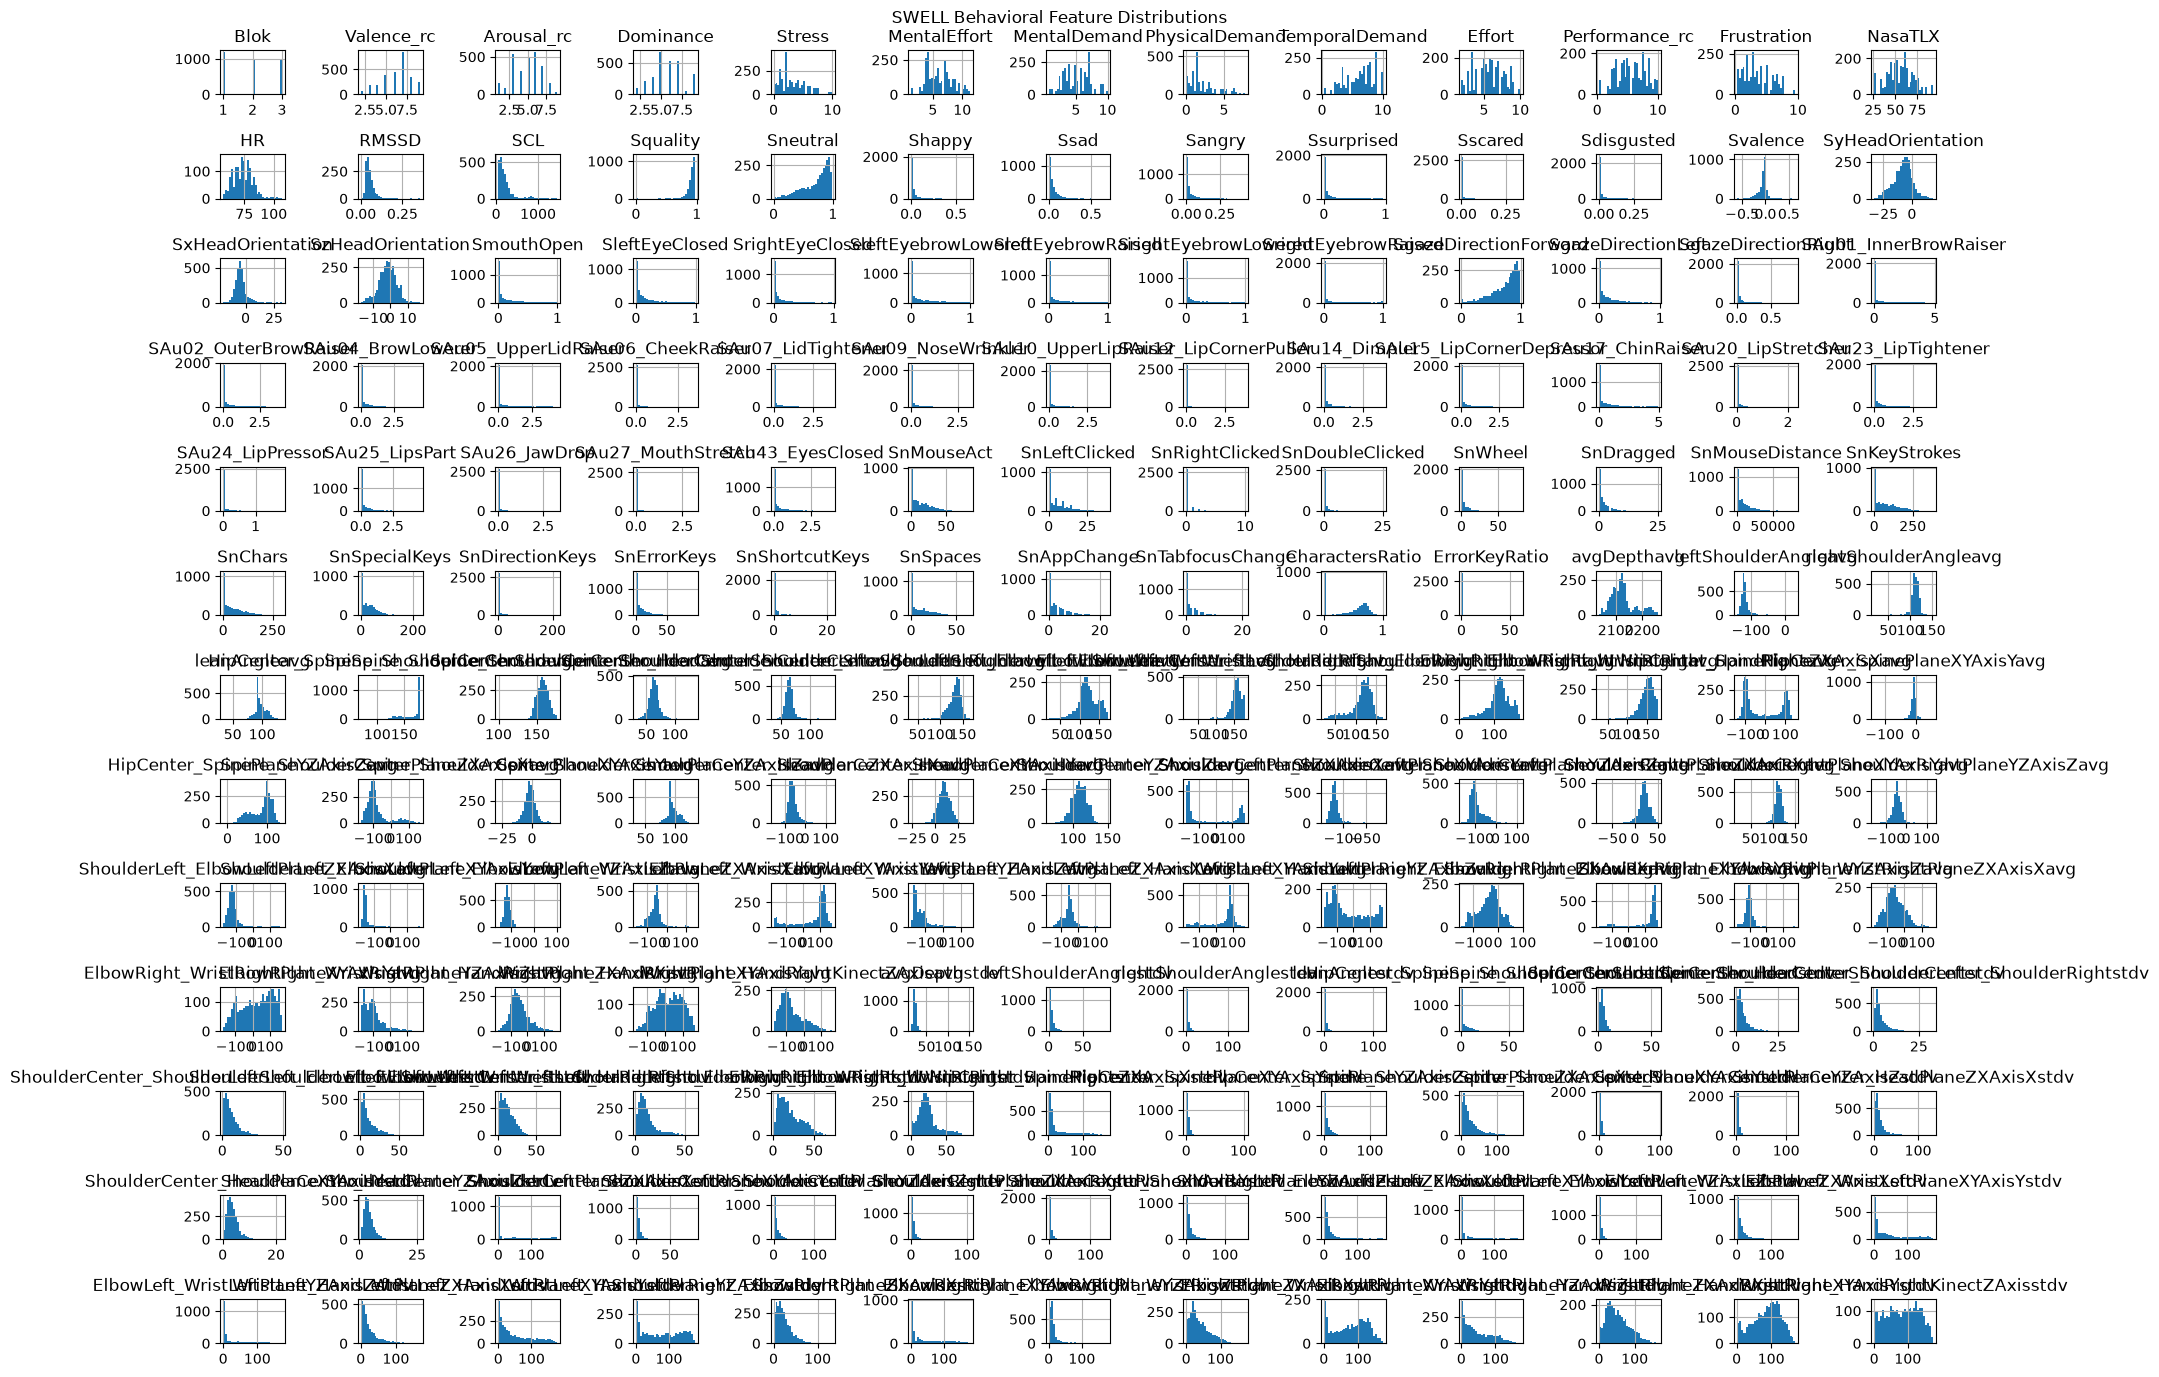

In [43]:
numeric_df = behavioral_df.select_dtypes(
    include=np.number
)

numeric_df.hist(
    figsize=(18, 14),
    bins=30
)

plt.suptitle(
    "SWELL Behavioral Feature Distributions"
)

plt.tight_layout()
plt.show()

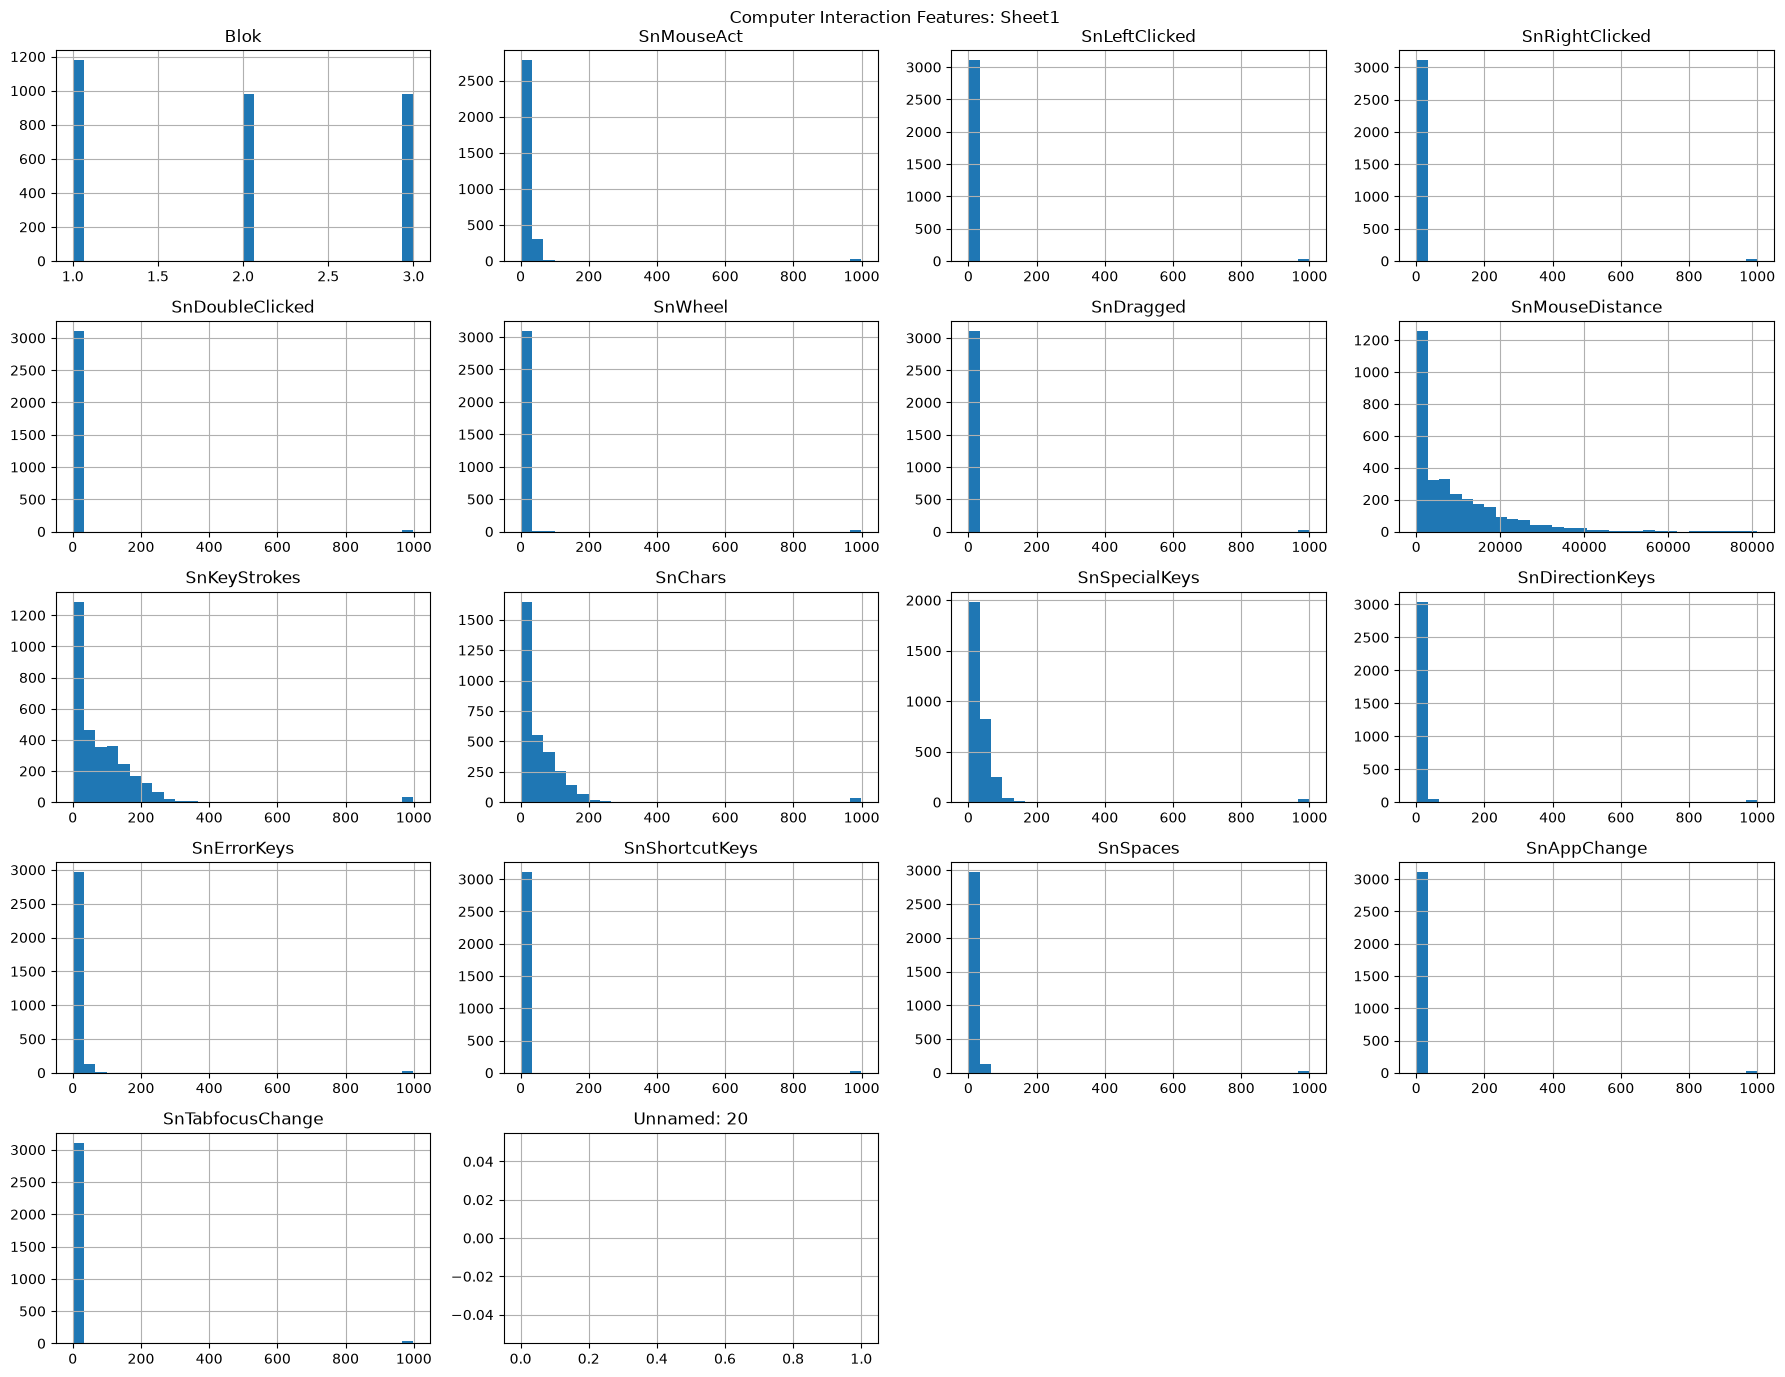

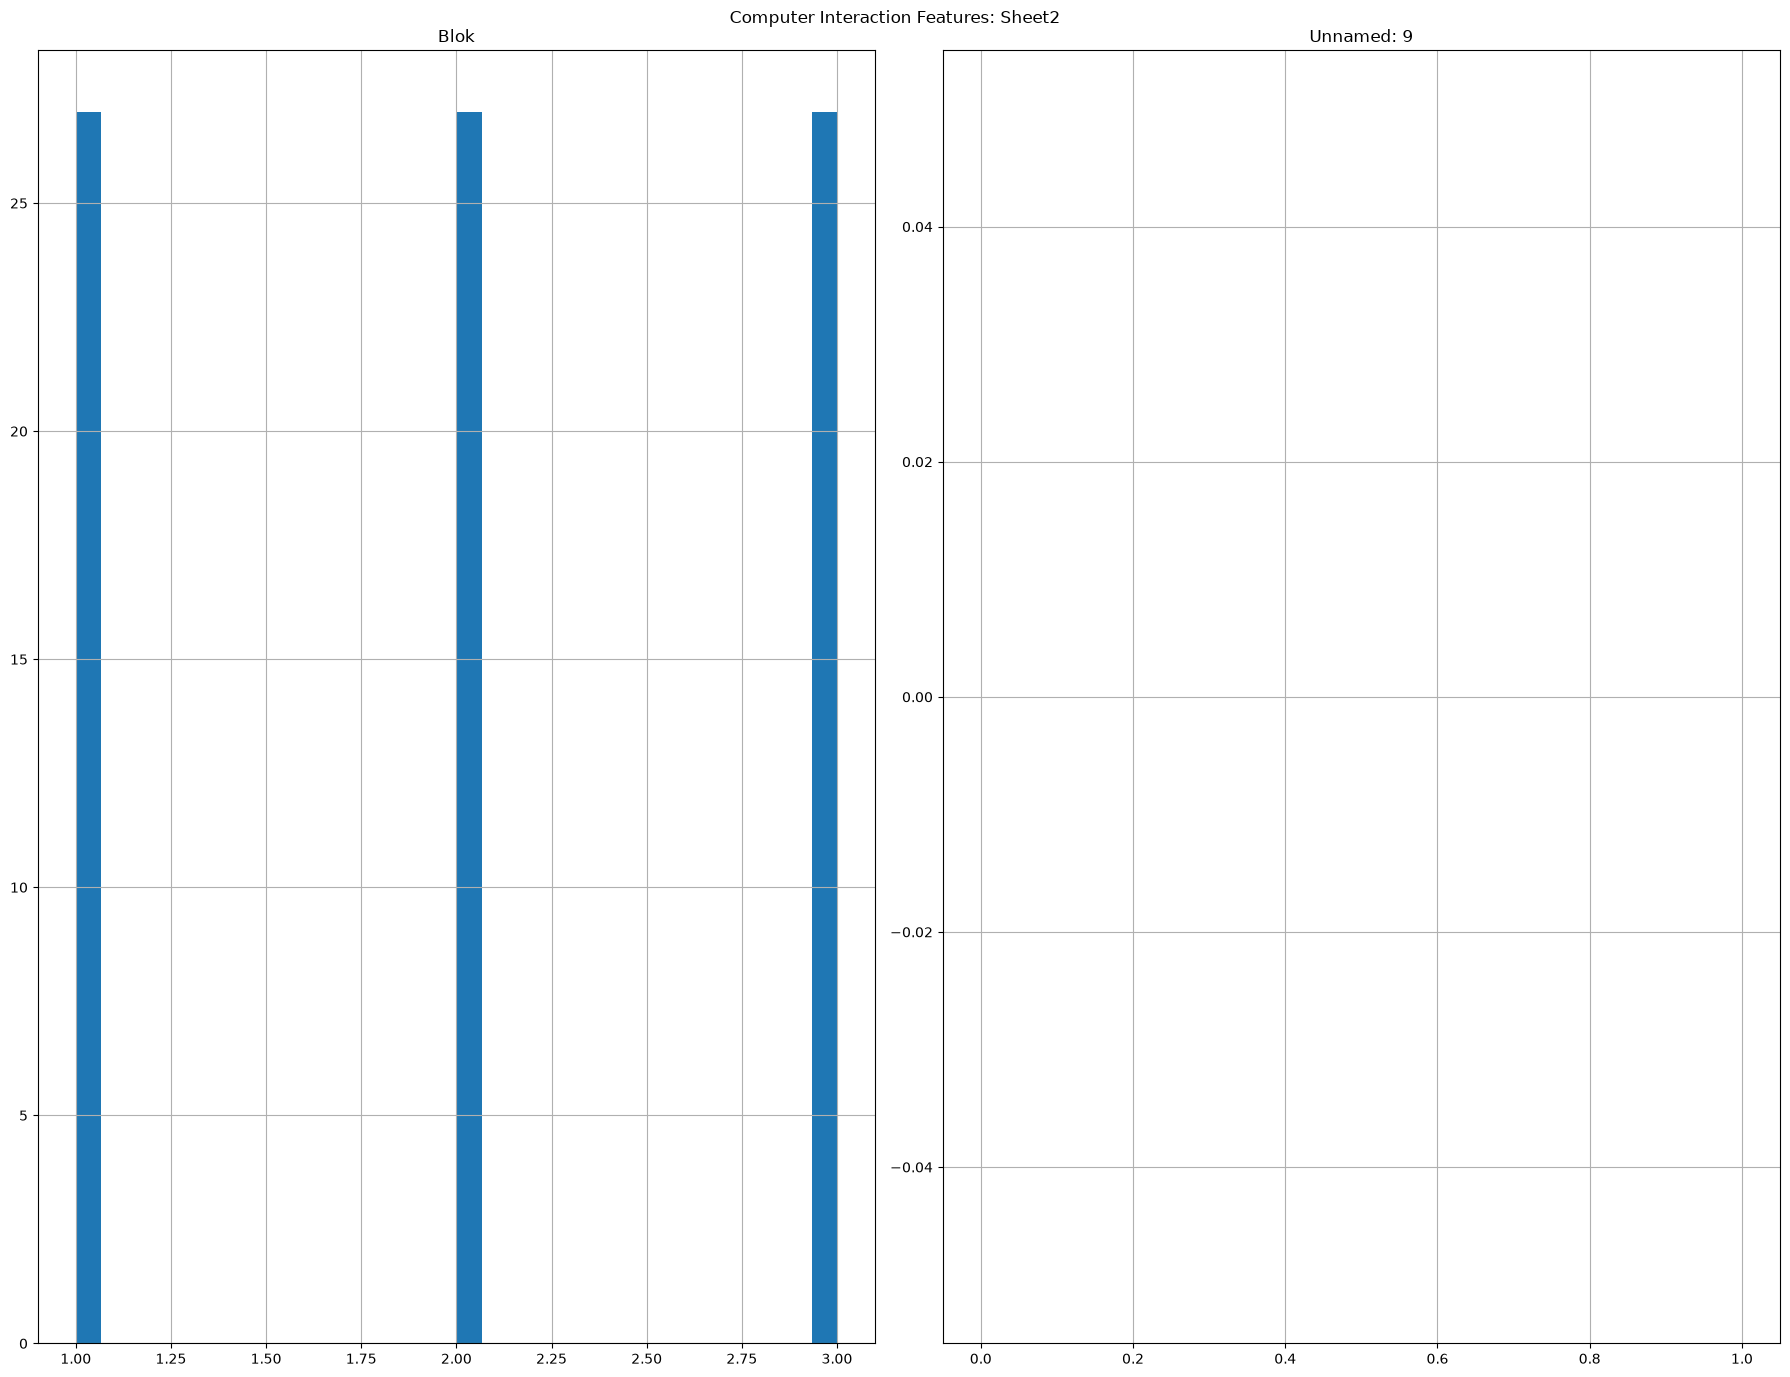

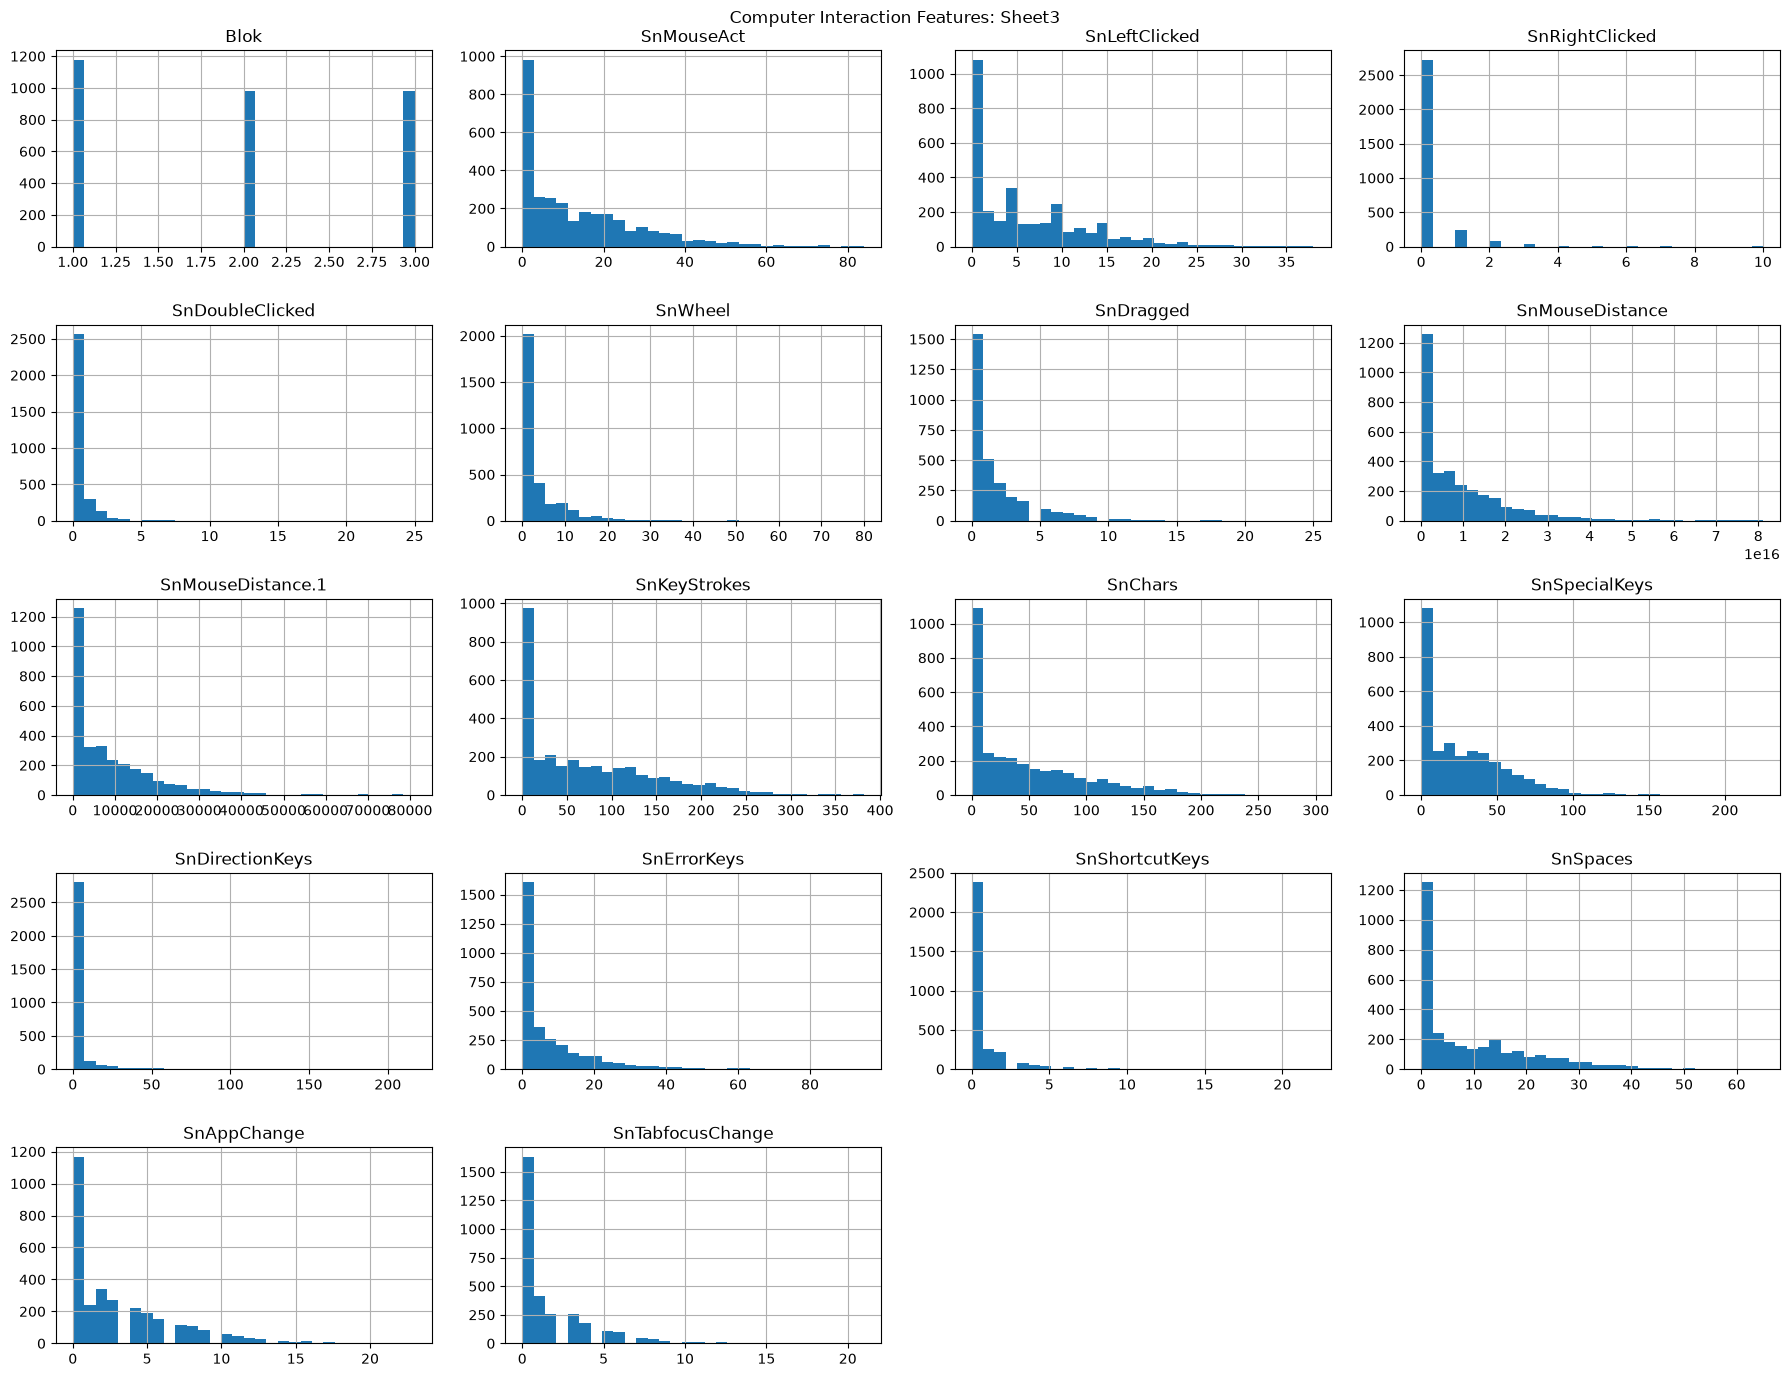

In [44]:
for sheet_name, df in computer_sheets.items():

    numeric_df = df.select_dtypes(
        include=np.number
    )

    numeric_df.hist(
        figsize=(18, 14),
        bins=30
    )

    plt.suptitle(
        f"Computer Interaction Features: {sheet_name}"
    )

    plt.tight_layout()
    plt.show()

### Correlation analysis

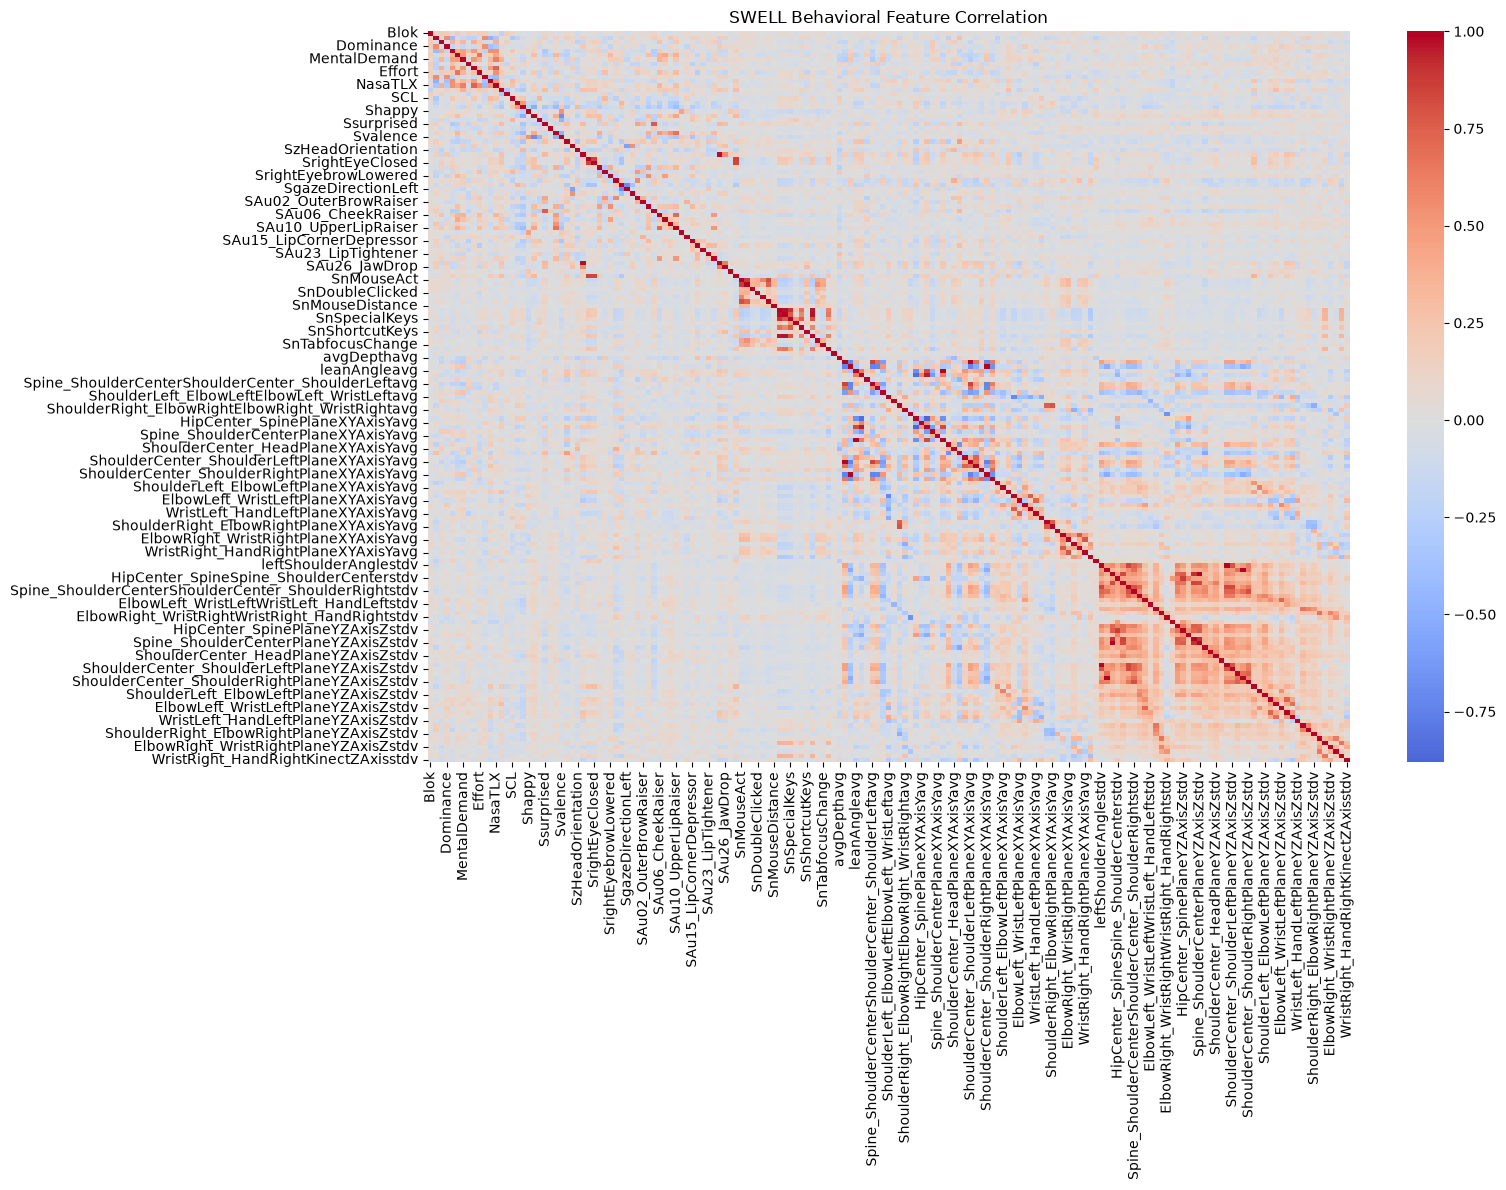

In [45]:
numeric_df = behavioral_df.select_dtypes(
    include=np.number
)

correlation = numeric_df.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0
)

plt.title(
    "SWELL Behavioral Feature Correlation"
)

plt.tight_layout()
plt.show()

In [46]:
sheet1 = computer_sheets["Sheet1"].copy()
sheet3 = computer_sheets["Sheet3"].copy()

print("Sheet1 shape:", sheet1.shape)
print("Sheet3 shape:", sheet3.shape)

print("\nSheet1 columns:")
print(sheet1.columns.tolist())

print("\nSheet3 columns:")
print(sheet3.columns.tolist())

print("\nSheet1 first 10 rows:")
display(sheet1.head(10))

print("\nSheet3 first 10 rows:")
display(sheet3.head(10))

Sheet1 shape: (3139, 22)
Sheet3 shape: (3140, 21)

Sheet1 columns:
['PP', 'Blok', 'Condition', 'timestamp', 'SnMouseAct', 'SnLeftClicked', 'SnRightClicked', 'SnDoubleClicked', 'SnWheel', 'SnDragged', 'SnMouseDistance', 'SnKeyStrokes', 'SnChars', 'SnSpecialKeys', 'SnDirectionKeys', 'SnErrorKeys', 'SnShortcutKeys', 'SnSpaces', 'SnAppChange', 'SnTabfocusChange', 'Unnamed: 20', 'Unnamed: 21']

Sheet3 columns:
['PP', 'Blok', 'Condition', 'timestamp', 'SnMouseAct', 'SnLeftClicked', 'SnRightClicked', 'SnDoubleClicked', 'SnWheel', 'SnDragged', 'SnMouseDistance', 'SnMouseDistance.1', 'SnKeyStrokes', 'SnChars', 'SnSpecialKeys', 'SnDirectionKeys', 'SnErrorKeys', 'SnShortcutKeys', 'SnSpaces', 'SnAppChange', 'SnTabfocusChange']

Sheet1 first 10 rows:


,PP,Blok,Condition,timestamp,SnMouseAct,SnLeftClicked,SnRightClicked,SnDoubleClicked,SnWheel,SnDragged,...,SnChars,SnSpecialKeys,SnDirectionKeys,SnErrorKeys,SnShortcutKeys,SnSpaces,SnAppChange,SnTabfocusChange,Unnamed: 20,Unnamed: 21
0,PP1,1,R,20120918T131600000,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,NaN,NaN
1,PP1,1,R,20120918T131700000,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,NaN,NaN
2,PP1,1,R,20120918T131800000,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,NaN,NaN
3,PP1,1,R,20120918T131900000,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,NaN,NaN
4,PP1,1,R,20120918T132000000,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,NaN,NaN
5,PP1,1,R,20120918T132100000,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,NaN,NaN
6,PP1,1,N,20120918T132600000,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,NaN,NaN
7,PP1,1,N,20120918T132700000,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,NaN,NaN
8,PP1,1,N,20120918T132800000,8,5,0,2,1,0,...,0,0,0,0,0,0,5,0,NaN,NaN
9,PP1,1,N,20120918T132900000,12,7,0,1,4,0,...,0,0,0,0,0,0,8,3,NaN,NaN



Sheet3 first 10 rows:


,PP,Blok,Condition,timestamp,SnMouseAct,SnLeftClicked,SnRightClicked,SnDoubleClicked,SnWheel,SnDragged,...,SnMouseDistance.1,SnKeyStrokes,SnChars,SnSpecialKeys,SnDirectionKeys,SnErrorKeys,SnShortcutKeys,SnSpaces,SnAppChange,SnTabfocusChange
0,PP1,1,R,20120918T131600000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,PP1,1,R,20120918T131700000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,PP1,1,R,20120918T131800000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,PP1,1,R,20120918T131900000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,PP1,1,R,20120918T132000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,PP1,1,R,20120918T132100000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,PP1,1,N,20120918T132600000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,PP1,1,N,20120918T132700000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,PP1,1,N,20120918T132800000,8.0,5.0,0.0,2.0,1.0,0.0,...,5691.235163,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,0.0
9,PP1,1,N,20120918T132900000,12.0,7.0,0.0,1.0,4.0,0.0,...,7726.999223,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.0,3.0


In [47]:
distance_columns = [
    col for col in sheet3.columns
    if "MouseDistance" in col
]

for col in distance_columns:
    print("\nColumn:", col)
    print("Data type:", sheet3[col].dtype)

    display(
        sheet3[col].describe()
    )

    display(
        sheet3[col].head(15)
    )


Column: SnMouseDistance
Data type: float64


count    3.140000e+03
mean     8.990366e+15
std      1.147427e+16
min      0.000000e+00
25%      0.000000e+00
50%      5.250134e+15
75%      1.345902e+16
max      8.109858e+16
Name: SnMouseDistance, dtype: float64

0     0.000000e+00
1     0.000000e+00
2     0.000000e+00
3     0.000000e+00
4     0.000000e+00
5     0.000000e+00
6     0.000000e+00
7     0.000000e+00
8     5.691235e+15
9     7.726999e+15
10    6.307768e+15
11    0.000000e+00
12    3.192022e+16
13    2.466927e+16
14    1.944811e+16
Name: SnMouseDistance, dtype: float64


Column: SnMouseDistance.1
Data type: float64


count     3138.000000
mean      8996.095680
std      11475.683012
min          0.000000
25%          0.000000
50%       5251.094913
75%      13465.599569
max      81098.584859
Name: SnMouseDistance.1, dtype: float64

0         0.000000
1         0.000000
2         0.000000
3         0.000000
4         0.000000
5         0.000000
6         0.000000
7         0.000000
8      5691.235163
9      7726.999223
10     6307.768271
11        0.000000
12    31920.220434
13    24669.271105
14    19448.107970
Name: SnMouseDistance.1, dtype: float64

In [48]:
display(
    sheet1["SnMouseDistance"].describe()
)

count     3137.000000
mean      8987.699156
std      11467.867690
min          0.000000
25%          0.000000
50%       5250.321702
75%      13455.723640
max      81098.584859
Name: SnMouseDistance, dtype: float64

In [49]:
for col in sheet1.columns:

    if pd.api.types.is_numeric_dtype(sheet1[col]):

        count_999 = (sheet1[col] == 999).sum()

        if count_999 > 0:

            print(
                col,
                "->",
                count_999,
                "values equal to 999"
            )

SnMouseAct -> 31 values equal to 999
SnLeftClicked -> 31 values equal to 999
SnRightClicked -> 31 values equal to 999
SnDoubleClicked -> 31 values equal to 999
SnWheel -> 31 values equal to 999
SnDragged -> 31 values equal to 999
SnMouseDistance -> 31 values equal to 999
SnKeyStrokes -> 31 values equal to 999
SnChars -> 31 values equal to 999
SnSpecialKeys -> 31 values equal to 999
SnDirectionKeys -> 31 values equal to 999
SnErrorKeys -> 31 values equal to 999
SnShortcutKeys -> 31 values equal to 999
SnSpaces -> 31 values equal to 999
SnAppChange -> 31 values equal to 999
SnTabfocusChange -> 31 values equal to 999


In [50]:
print("Unique participants:")
print(sheet1["PP"].nunique())

print("\nParticipants:")
print(sorted(sheet1["PP"].dropna().unique()))

print("\nCondition distribution:")
print(sheet1["Condition"].value_counts(dropna=False))

print("\nBlock distribution:")
print(sheet1["Blok"].value_counts(dropna=False))

print("\nParticipant-condition combinations:")
display(
    sheet1.groupby(
        ["PP", "Condition"]
    ).size().reset_index(name="records")
)

Unique participants:
25

Participants:
['PP1', 'PP10', 'PP11', 'PP12', 'PP13', 'PP14', 'PP15', 'PP16', 'PP17', 'PP18', 'PP19', 'PP2', 'PP20', 'PP21', 'PP22', 'PP23', 'PP24', 'PP25', 'PP3', 'PP4', 'PP5', 'PP6', 'PP7', 'PP8', 'PP9']

Condition distribution:
Condition
N    1028
I     996
T     664
R     451
Name: count, dtype: int64

Block distribution:
Blok
1    1178
2     981
3     980
Name: count, dtype: int64

Participant-condition combinations:


,PP,Condition,records
0,PP1,I,42
1,PP1,N,42
2,PP1,R,18
3,PP1,T,27
4,PP10,I,41
...,...,...,...
95,PP8,T,24
96,PP9,I,39
97,PP9,N,38
98,PP9,R,18


In [51]:
target_columns = [
    "Stress",
    "MentalEffort",
    "MentalDemand",
    "Effort",
    "Performance_rc",
    "NasaTLX"
]

for col in target_columns:

    print("\n", col)

    if col in behavioral_df.columns:

        print("Missing:", behavioral_df[col].isna().sum())

        print("Unique:", behavioral_df[col].nunique())

        display(
            behavioral_df[col].describe()
        )


 Stress
Missing: 451
Unique: 53


count    2688.000000
mean        3.214509
std         2.152607
min         0.000000
25%         1.400000
50%         2.800000
75%         4.700000
max        10.000000
Name: Stress, dtype: float64


 MentalEffort
Missing: 451
Unique: 45


count    2688.000000
mean        6.147693
std         2.211866
min         1.300000
25%         4.100000
50%         5.700000
75%         7.700000
max        11.300000
Name: MentalEffort, dtype: float64


 MentalDemand
Missing: 451
Unique: 41


count    2688.000000
mean        5.118638
std         2.069850
min         0.700000
25%         3.300000
50%         5.000000
75%         6.800000
max        10.000000
Name: MentalDemand, dtype: float64

... (2 outputs left out)


 Performance_rc
Missing: 451
Unique: 46


count    2688.000000
mean        5.615476
std         2.333585
min         0.300000
25%         3.900000
50%         5.300000
75%         7.700000
max        10.000000
Name: Performance_rc, dtype: float64


 NasaTLX
Missing: 554
Unique: 65


count    2585.000000
mean       55.948549
std        14.440894
min        26.100000
25%        45.400000
50%        55.800000
75%        64.000000
max        92.600000
Name: NasaTLX, dtype: float64

Computer feature columns:
['SnMouseAct', 'SnLeftClicked', 'SnRightClicked', 'SnDoubleClicked', 'SnWheel', 'SnDragged', 'SnMouseDistance', 'SnKeyStrokes', 'SnChars', 'SnSpecialKeys', 'SnDirectionKeys', 'SnErrorKeys', 'SnShortcutKeys', 'SnSpaces', 'SnAppChange', 'SnTabfocusChange']


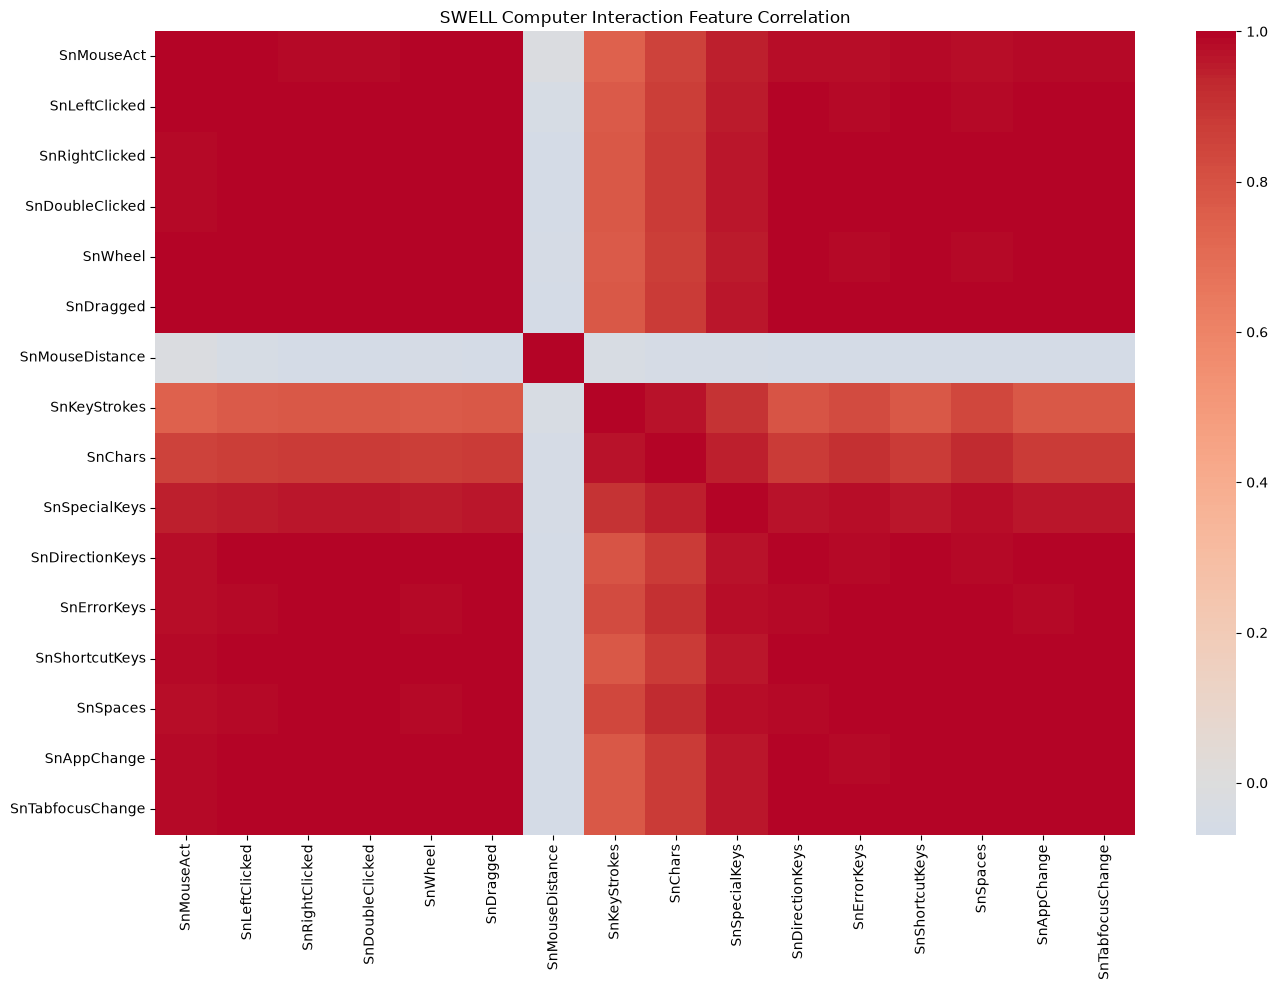

In [52]:
computer_feature_columns = [
    col for col in sheet1.columns
    if col.startswith("Sn")
]

print("Computer feature columns:")
print(computer_feature_columns)

computer_numeric = sheet1[
    computer_feature_columns
].select_dtypes(include=np.number)

plt.figure(figsize=(14, 10))

sns.heatmap(
    computer_numeric.corr(),
    cmap="coolwarm",
    center=0
)

plt.title("SWELL Computer Interaction Feature Correlation")

plt.tight_layout()
plt.show()

In [53]:
# Remove completely empty columns
sheet1_clean = sheet1.dropna(axis=1, how="all").copy()
sheet3_clean = sheet3.dropna(axis=1, how="all").copy()

print("Sheet1:", sheet1_clean.shape)
print("Sheet3:", sheet3_clean.shape)

# Compare common columns
common_cols = list(
    set(sheet1_clean.columns) & set(sheet3_clean.columns)
)

print("\nCommon columns:")
print(common_cols)

# Compare records using participant, block and timestamp
keys = ["PP", "Blok", "Condition", "timestamp"]

print("\nDuplicate keys in Sheet1:")
print(sheet1_clean.duplicated(keys).sum())

print("\nDuplicate keys in Sheet3:")
print(sheet3_clean.duplicated(keys).sum())

comparison = sheet1_clean[keys].merge(
    sheet3_clean[keys],
    on=keys,
    how="outer",
    indicator=True
)

print("\nRecord alignment:")
print(comparison["_merge"].value_counts())

Sheet1: (3139, 21)
Sheet3: (3140, 21)

Common columns:
['SnChars', 'PP', 'SnErrorKeys', 'SnRightClicked', 'SnSpaces', 'SnAppChange', 'SnShortcutKeys', 'Blok', 'SnMouseAct', 'SnLeftClicked', 'SnWheel', 'SnDoubleClicked', 'SnKeyStrokes', 'SnMouseDistance', 'SnSpecialKeys', 'SnDirectionKeys', 'timestamp', 'Condition', 'SnDragged', 'SnTabfocusChange']

Duplicate keys in Sheet1:
0

Duplicate keys in Sheet3:
0

Record alignment:
_merge
both          3139
right_only       1
left_only        0
Name: count, dtype: int64


In [54]:
print("Sheet1 mouse distance:")
display(sheet1["SnMouseDistance"].describe())

print("\nSheet3 original mouse distance:")
display(sheet3["SnMouseDistance"].describe())

print("\nSheet3 duplicate mouse distance:")
display(sheet3["SnMouseDistance.1"].describe())

print("\nCompare Sheet1 and Sheet3 duplicate distance:")

distance_comparison = pd.DataFrame({
    "Sheet1": sheet1["SnMouseDistance"].reset_index(drop=True),
    "Sheet3_duplicate": sheet3["SnMouseDistance.1"].reset_index(drop=True)
})

display(distance_comparison.head(20))

print(
    "Correlation:",
    distance_comparison.corr().iloc[0, 1]
)

Sheet1 mouse distance:


count     3137.000000
mean      8987.699156
std      11467.867690
min          0.000000
25%          0.000000
50%       5250.321702
75%      13455.723640
max      81098.584859
Name: SnMouseDistance, dtype: float64


Sheet3 original mouse distance:


count    3.140000e+03
mean     8.990366e+15
std      1.147427e+16
min      0.000000e+00
25%      0.000000e+00
50%      5.250134e+15
75%      1.345902e+16
max      8.109858e+16
Name: SnMouseDistance, dtype: float64


Sheet3 duplicate mouse distance:


count     3138.000000
mean      8996.095680
std      11475.683012
min          0.000000
25%          0.000000
50%       5251.094913
75%      13465.599569
max      81098.584859
Name: SnMouseDistance.1, dtype: float64


Compare Sheet1 and Sheet3 duplicate distance:


,Sheet1,Sheet3_duplicate
0,0.000000,0.000000
1,0.000000,0.000000
2,0.000000,0.000000
3,0.000000,0.000000
4,0.000000,0.000000
5,0.000000,0.000000
6,0.000000,0.000000
7,0.000000,0.000000
8,5691.235163,5691.235163
9,7726.999223,7726.999223


Correlation: 0.19560132058197605


In [55]:
invalid_rows = sheet1[
    (sheet1.select_dtypes(include=np.number) == 999).any(axis=1)
]

print("Rows containing 999:", len(invalid_rows))

display(
    invalid_rows[
        ["PP", "Blok", "Condition", "timestamp"]
    ]
)

print("\n999 counts by feature:")

display(
    (sheet1.select_dtypes(include=np.number) == 999).sum()
)

Rows containing 999: 31


,PP,Blok,Condition,timestamp
1358,PP11,3,I,20121009T115500000
1359,PP11,3,I,20121009T115600000
1360,PP11,3,I,20121009T115700000
1361,PP11,3,I,20121009T115800000
1362,PP11,3,I,20121009T115900000
1363,PP11,3,I,20121009T120000000
1364,PP11,3,I,20121009T120100000
1365,PP11,3,I,20121009T120200000
1366,PP11,3,I,20121009T120300000
1367,PP11,3,I,20121009T120400000



999 counts by feature:


Blok                 0
SnMouseAct          31
SnLeftClicked       31
SnRightClicked      31
SnDoubleClicked     31
SnWheel             31
SnDragged           31
SnMouseDistance     31
SnKeyStrokes        31
SnChars             31
SnSpecialKeys       31
SnDirectionKeys     31
SnErrorKeys         31
SnShortcutKeys      31
SnSpaces            31
SnAppChange         31
SnTabfocusChange    31
Unnamed: 20          0
dtype: int64

In [56]:
print("Behavioral data:")
display(
    behavioral_df[
        ["PP", "Blok", "Condition", "timestamp",
         "Stress", "MentalEffort", "MentalDemand",
         "Effort", "Performance_rc", "NasaTLX"]
    ].head(20)
)

print("\nBlock questionnaire columns:")
print(questionnaire_block.columns.tolist())

display(questionnaire_block.head(10))

Behavioral data:


,PP,Blok,Condition,timestamp,Stress,MentalEffort,MentalDemand,Effort,Performance_rc,NasaTLX
0,PP1,1,R,20120918T131600000,NaN,NaN,NaN,NaN,NaN,NaN
1,PP1,1,R,20120918T131700000,NaN,NaN,NaN,NaN,NaN,NaN
2,PP1,1,R,20120918T131800000,NaN,NaN,NaN,NaN,NaN,NaN
3,PP1,1,R,20120918T131900000,NaN,NaN,NaN,NaN,NaN,NaN
4,PP1,1,R,20120918T132000000,NaN,NaN,NaN,NaN,NaN,NaN
5,PP1,1,R,20120918T132100000,NaN,NaN,NaN,NaN,NaN,NaN
6,PP1,1,N,20120918T132600000,4.1,5.1,0.7,5.0,4.9,50.7
7,PP1,1,N,20120918T132700000,4.1,5.1,0.7,5.0,4.9,50.7
8,PP1,1,N,20120918T132800000,4.1,5.1,0.7,5.0,4.9,50.7
9,PP1,1,N,20120918T132900000,4.1,5.1,0.7,5.0,4.9,50.7



Block questionnaire columns:
['PP', 'Blok', 'Condition', 'Unnamed: 3', 'Valence', 'Valnce (recoded)', 'Arousal', 'Arousal (recoded)', 'Dominance', 'Unnamed: 9', 'Stress', 'MentalEffort', 'Task Load…', 'MentalDemand', 'PhysicalDemand', 'TemporalDemand', 'Effort', 'Performance', 'Performance (recoded)', 'Frustration', 'Weights…', 'MentalAspects', 'TemporalAspects', 'EffortAspects', 'PerformanceAspects', 'FrustrationAspects', 'Checksum = 10', 'Topic1', 'done?', 'Topic2', 'done?.1', 'PresentationOn', 'Unnamed: 32', '#Pres', '#Rep', 'Unnamed: 35', 'DifficultReport1', 'DifficultReport2', 'DifficultPresentation', 'Average of done', 'Unnamed: 40', 'InterestTopic1', 'InterestTopic2', 'Average over done', 'Unnamed: 44', 'Unnamed: 45', 'Comments']


,PP,Blok,Condition,Unnamed: 3,Valence,Valnce (recoded),Arousal,Arousal (recoded),Dominance,Unnamed: 9,...,DifficultReport2,DifficultPresentation,Average of done,Unnamed: 40,InterestTopic1,InterestTopic2,Average over done,Unnamed: 44,Unnamed: 45,Comments
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,SP,1.0,N,NaN,6.0,3.0,3.0,6.0,5.0,NaN,...,2,0,NaN,NaN,3,3,NaN,NaN,NaN,Unclear expectations regarding reports.
2,SP,2.0,I,NaN,4.0,5.0,5.0,4.0,7.0,NaN,...,4,1,NaN,NaN,1,5,NaN,NaN,NaN,NaN
3,SP,3.0,T,NaN,3.0,6.0,3.0,6.0,3.0,NaN,...,5,1,NaN,NaN,1,0,NaN,NaN,NaN,NaN
4,MP,1.0,N,NaN,2.0,7.0,4.0,5.0,5.0,NaN,...,3,1,NaN,NaN,4,5,NaN,NaN,NaN,NaN
5,MP,2.0,T,NaN,5.0,4.0,3.0,6.0,4.0,NaN,...,5,2,NaN,NaN,3,4,NaN,NaN,NaN,NaN
6,MP,3.0,I,NaN,3.0,6.0,5.0,4.0,7.0,NaN,...,2,1,NaN,NaN,4,4,NaN,NaN,NaN,NaN
7,1,1.0,N,NaN,4.0,5.0,6.0,3.0,6.0,NaN,...,0,**,0.500000,NaN,3,5,4.0,NaN,NaN,Niet aan presentatie toegekomen.
8,1,2.0,T,NaN,4.0,5.0,5.0,4.0,7.0,NaN,...,1,1,1.333333,NaN,4,3,3.5,NaN,NaN,Beter verdelen van de tijd over de 3 taken. Ik...
9,1,3.0,I,NaN,5.0,4.0,3.0,6.0,4.0,NaN,...,1,0,1.000000,NaN,3,4,3.5,NaN,NaN,Prioriteiten stellen in het geval van mail. Ve...


In [57]:
print("Questionnaire block shape:", questionnaire_block.shape)

for col in questionnaire_block.columns:

    if any(
        word in col.lower()
        for word in [
            "pp", "blok", "condition",
            "stress", "effort", "demand",
            "performance", "tlx"
        ]
    ):

        print("\n", col)
        print(questionnaire_block[col].value_counts(dropna=False).head(10))

Questionnaire block shape: (89, 47)

 PP
PP
NaN    8
SP     3
MP     3
1      3
2      3
3      3
4      3
5      3
6      3
7      3
Name: count, dtype: int64

 Blok
Blok
1.0    27
2.0    27
3.0    27
NaN     8
Name: count, dtype: int64

 Condition
Condition
N      27
I      27
T      27
NaN     8
Name: count, dtype: int64

 Stress
Stress
NaN    6
2.0    6
1.3    6
2.8    3
1.5    3
2.2    3
2.3    3
5.7    2
3.3    2
3.8    2
Name: count, dtype: int64

 MentalEffort
MentalEffort
NaN    8
3.8    7
7.2    7
5.7    4
4.1    4
4.0    3
5.6    2
3.9    2
4.2    2
4.9    2
Name: count, dtype: int64

 MentalDemand
MentalDemand
NaN    8
3.3    7
7.0    7
6.8    4
5.8    4
3.0    4
2.3    3
3.8    3
4.0    3
6.5    3
Name: count, dtype: int64

 PhysicalDemand
PhysicalDemand
1.3    9
NaN    8
1.0    8
0.3    6
0.2    5
1.4    4
1.5    4
3.0    4
2.2    3
0.7    2
Name: count, dtype: int64

 TemporalDemand
TemporalDemand
NaN    8
8.0    4
6.3    4
7.0    4
9.0    4
7.8    3
5.7    3
4.3    3
7.

### Cell 39

In [58]:
keys = ["PP", "Blok", "Condition", "timestamp"]

sheet1_check = sheet1_clean.copy()
sheet3_check = sheet3_clean.copy()

merged = sheet1_check.merge(
    sheet3_check,
    on=keys,
    how="inner",
    suffixes=("_s1", "_s3"),
    validate="one_to_one"
)

print("Matched records:", len(merged))

# Compare the duplicate mouse-distance columns
distance_check = pd.DataFrame({
    "Sheet1": merged["SnMouseDistance_s1"],
    "Sheet3_duplicate": merged["SnMouseDistance.1"]
})

display(distance_check.describe())

print(
    "Correlation:",
    distance_check.corr().iloc[0, 1]
)

print(
    "Maximum absolute difference:",
    (distance_check["Sheet1"] -
     distance_check["Sheet3_duplicate"]).abs().max()
)

print(
    "Exactly equal:",
    np.allclose(
        distance_check["Sheet1"],
        distance_check["Sheet3_duplicate"],
        equal_nan=True
    )
)

Matched records: 3139


,Sheet1,Sheet3_duplicate
count,3137.000000,3137.000000
mean,8987.699156,8987.699156
std,11467.867690,11467.867690
min,0.000000,0.000000
25%,0.000000,0.000000
50%,5250.321702,5250.321702
75%,13455.723640,13455.723640
max,81098.584859,81098.584859


Correlation: 1.0
Maximum absolute difference: 0.0
Exactly equal: True


In [59]:
ratio = (
    merged["SnMouseDistance_s3"] /
    merged["SnMouseDistance_s1"].replace(0, np.nan)
)

print("Sheet3 original / Sheet1 ratio:")
display(ratio.describe())

Sheet3 original / Sheet1 ratio:


count    2.324000e+03
mean     1.000000e+12
std      5.612110e-05
min      1.000000e+12
25%      1.000000e+12
50%      1.000000e+12
75%      1.000000e+12
max      1.000000e+12
dtype: float64

In [60]:
feature_cols = [
    col for col in sheet1_clean.columns
    if col.startswith("Sn")
]

invalid_mask = (
    sheet1_clean[feature_cols] == 999
).any(axis=1)

print("Invalid rows:", invalid_mask.sum())

print("\nInvalid rows by participant:")
display(
    sheet1_clean.loc[invalid_mask]
    .groupby(["PP", "Blok", "Condition"])
    .size()
)

print("\nDo all feature columns contain 999 together?")

display(
    (
        sheet1_clean.loc[invalid_mask, feature_cols] == 999
    ).all(axis=1).value_counts()
)

Invalid rows: 31

Invalid rows by participant:


PP    Blok  Condition
PP11  3     I            21
PP16  2     I            10
dtype: int64


Do all feature columns contain 999 together?


True    31
Name: count, dtype: int64

In [61]:
sheet1_cleaned = sheet1_clean.copy()

sheet1_cleaned[feature_cols] = (
    sheet1_cleaned[feature_cols]
    .replace(999, np.nan)
)

print("Remaining 999 values:")
print(
    (sheet1_cleaned[feature_cols] == 999).sum().sum()
)

print("Missing feature values:")
print(sheet1_cleaned[feature_cols].isna().sum())

Remaining 999 values:
0
Missing feature values:
SnMouseAct          31
SnLeftClicked       31
SnRightClicked      31
SnDoubleClicked     31
SnWheel             31
SnDragged           31
SnMouseDistance     33
SnKeyStrokes        31
SnChars             31
SnSpecialKeys       31
SnDirectionKeys     31
SnErrorKeys         31
SnShortcutKeys      31
SnSpaces            31
SnAppChange         31
SnTabfocusChange    31
dtype: int64


In [62]:
print("Questionnaire participant values:")

display(
    questionnaire_block["PP"]
    .value_counts(dropna=False)
)

print("\nQuestionnaire block values:")

display(
    questionnaire_block["Blok"]
    .value_counts(dropna=False)
)

print("\nComputer dataset participants:")
print(sorted(sheet1_clean["PP"].dropna().unique()))

Questionnaire participant values:


PP
NaN    8
SP     3
MP     3
1      3
2      3
3      3
4      3
5      3
6      3
7      3
8      3
9      3
10     3
11     3
12     3
13     3
14     3
15     3
16     3
17     3
18     3
19     3
20     3
21     3
22     3
23     3
24     3
25     3
Name: count, dtype: int64


Questionnaire block values:


Blok
1.0    27
2.0    27
3.0    27
NaN     8
Name: count, dtype: int64


Computer dataset participants:
['PP1', 'PP10', 'PP11', 'PP12', 'PP13', 'PP14', 'PP15', 'PP16', 'PP17', 'PP18', 'PP19', 'PP2', 'PP20', 'PP21', 'PP22', 'PP23', 'PP24', 'PP25', 'PP3', 'PP4', 'PP5', 'PP6', 'PP7', 'PP8', 'PP9']


In [63]:
valid_questionnaire = questionnaire_block[
    questionnaire_block["PP"].notna()
].copy()

display(
    valid_questionnaire[
        [
            "PP",
            "Blok",
            "Condition",
            "Stress",
            "MentalEffort",
            "MentalDemand",
            "Effort",
            "Performance",
            "Frustration"
        ]
    ]
)

,PP,Blok,Condition,Stress,MentalEffort,MentalDemand,Effort,Performance,Frustration
1,SP,1.0,N,5.7,4.3,3.3,6.3,4.3,1.4
2,SP,2.0,I,3.3,5.6,4.3,7.2,5.3,4.8
3,SP,3.0,T,3.8,3.8,4.7,4.7,3.7,4.9
4,MP,1.0,N,2.8,5.7,5.9,6.3,0.7,0.7
5,MP,2.0,T,5.3,7.2,6.8,7.0,4.6,6.2
...,...,...,...,...,...,...,...,...,...
77,24,2.0,T,7.4,4.1,4.9,6.5,7.0,7.6
78,24,3.0,I,1.3,5.7,5.0,5.6,2.5,6.0
79,25,1.0,N,2.3,3.8,7.9,2.9,3.3,6.7
80,25,2.0,I,0.4,5.5,7.4,3.8,1.3,1.6


In [64]:
label_cols = [
    "Stress",
    "MentalEffort",
    "MentalDemand",
    "Effort",
    "Performance_rc",
    "NasaTLX"
]

grouped_labels = (
    behavioral_df
    .groupby(["PP", "Blok", "Condition"])[label_cols]
    .nunique(dropna=True)
)

print("Number of distinct label values within each block:")

display(grouped_labels.describe())

print("\nGroups with changing MentalEffort labels:")

display(
    grouped_labels[
        grouped_labels["MentalEffort"] > 1
    ]
)

Number of distinct label values within each block:


,Stress,MentalEffort,MentalDemand,Effort,Performance_rc,NasaTLX
count,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000
mean,0.500000,0.500000,0.500000,0.500000,0.500000,0.480000
std,0.501675,0.501675,0.501675,0.501675,0.501675,0.501274
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.500000,0.500000,0.500000,0.500000,0.500000,0.000000
75%,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000



Groups with changing MentalEffort labels:


,,,Stress,MentalEffort,MentalDemand,Effort,Performance_rc,NasaTLX
PP,Blok,Condition,,,,,,


In [65]:
computer_groups = (
    sheet1_clean
    .groupby(["PP", "Blok", "Condition"])
    .size()
    .reset_index(name="computer_records")
)

behavior_groups = (
    behavioral_df
    .groupby(["PP", "Blok", "Condition"])
    .size()
    .reset_index(name="behavior_records")
)

coverage = computer_groups.merge(
    behavior_groups,
    on=["PP", "Blok", "Condition"],
    how="outer",
    indicator=True
)

print("Group alignment:")
display(coverage["_merge"].value_counts())

display(
    coverage[coverage["_merge"] != "both"]
)

Group alignment:


_merge
both          150
left_only       0
right_only      0
Name: count, dtype: int64

,PP,Blok,Condition,computer_records,behavior_records,_merge


In [66]:
label_cols = [
    "Stress",
    "MentalEffort",
    "MentalDemand",
    "Effort",
    "Performance_rc",
    "NasaTLX"
]

label_missing = (
    behavioral_df
    .groupby(["PP", "Blok", "Condition"])[label_cols]
    .agg(lambda x: x.isna().all())
)

print("Groups where all values for each label are missing:")
display(label_missing.sum())

print("\nGroups with at least one missing label:")
display(
    label_missing[
        label_missing.any(axis=1)
    ]
)

Groups where all values for each label are missing:


Stress            75
MentalEffort      75
MentalDemand      75
Effort            75
Performance_rc    75
NasaTLX           78
dtype: int64


Groups with at least one missing label:


Stress  MentalEffort  MentalDemand  Effort  \
PP   Blok Condition                                               
PP1  1    R            True          True          True    True   
     2    R            True          True          True    True   
     3    R            True          True          True    True   
PP10 1    R            True          True          True    True   
     2    R            True          True          True    True   
...                     ...           ...           ...     ...   
PP8  2    R            True          True          True    True   
     3    R            True          True          True    True   
PP9  1    R            True          True          True    True   
     2    R            True          True          True    True   
     3    R            True          True          True    True   

                     Performance_rc  NasaTLX  
PP   Blok Condition                           
PP1  1    R                    True     True  
     2    R                    True     True  
     3    R                    True     True  
PP10 1    R                    True     True  
     2    R                    True     True  
...                             ...      ...  
PP8  2    R                    True     True  
     3    R                    True     True  
PP9  1    R                    True     True  
     2    R                    True     True  
     3    R                    True     True  

[78 rows x 6 columns]

In [67]:
questionnaire_clean = questionnaire_block.copy()

questionnaire_clean = questionnaire_clean[
    questionnaire_clean["PP"].notna()
].copy()

questionnaire_clean["PP"] = (
    questionnaire_clean["PP"]
    .astype(str)
    .str.strip()
    .apply(
        lambda x: f"PP{x}" if x.isdigit() else x
    )
)

print("Normalized participant IDs:")
print(questionnaire_clean["PP"].value_counts())

print("\nQuestionnaire rows:")
print(len(questionnaire_clean))

print("\nDuplicate participant/block/condition combinations:")
display(
    questionnaire_clean[
        questionnaire_clean.duplicated(
            ["PP", "Blok", "Condition"],
            keep=False
        )
    ]
)

Normalized participant IDs:
PP
SP      3
MP      3
PP1     3
PP2     3
PP3     3
PP4     3
PP5     3
PP6     3
PP7     3
PP8     3
PP9     3
PP10    3
PP11    3
PP12    3
PP13    3
PP14    3
PP15    3
PP16    3
PP17    3
PP18    3
PP19    3
PP20    3
PP21    3
PP22    3
PP23    3
PP24    3
PP25    3
Name: count, dtype: int64

Questionnaire rows:
81

Duplicate participant/block/condition combinations:


,PP,Blok,Condition,Unnamed: 3,Valence,Valnce (recoded),Arousal,Arousal (recoded),Dominance,Unnamed: 9,...,DifficultReport2,DifficultPresentation,Average of done,Unnamed: 40,InterestTopic1,InterestTopic2,Average over done,Unnamed: 44,Unnamed: 45,Comments


In [68]:
comparison = behavioral_df[
    ["PP", "Blok", "Condition", "MentalEffort"]
].drop_duplicates()

questionnaire_labels = questionnaire_clean[
    ["PP", "Blok", "Condition", "MentalEffort"]
].drop_duplicates()

label_comparison = comparison.merge(
    questionnaire_labels,
    on=["PP", "Blok", "Condition"],
    how="left",
    suffixes=("_behavior", "_questionnaire"),
    indicator=True
)

print("Mapping status:")
display(label_comparison["_merge"].value_counts())

print("\nLabel mismatches:")
mismatch = label_comparison[
    label_comparison["MentalEffort_behavior"].notna()
    & label_comparison["MentalEffort_questionnaire"].notna()
    & (
        label_comparison["MentalEffort_behavior"]
        != label_comparison["MentalEffort_questionnaire"]
    )
]

display(mismatch)

print("\nMissing questionnaire labels:")
display(
    label_comparison[
        label_comparison["MentalEffort_questionnaire"].isna()
    ]
)

Mapping status:


_merge
left_only     75
both          75
right_only     0
Name: count, dtype: int64


Label mismatches:


,PP,Blok,Condition,MentalEffort_behavior,MentalEffort_questionnaire,_merge



Missing questionnaire labels:


,PP,Blok,Condition,MentalEffort_behavior,MentalEffort_questionnaire,_merge
0,PP1,1,R,NaN,NaN,left_only
2,PP1,2,R,NaN,NaN,left_only
4,PP1,3,R,NaN,NaN,left_only
6,PP2,1,R,NaN,NaN,left_only
8,PP2,2,R,NaN,NaN,left_only
...,...,...,...,...,...,...
140,PP24,2,R,NaN,NaN,left_only
142,PP24,3,R,NaN,NaN,left_only
144,PP25,1,R,NaN,NaN,left_only
146,PP25,2,R,NaN,NaN,left_only


In [69]:
label_cols = [
    "Stress",
    "MentalEffort",
    "MentalDemand",
    "Effort",
    "Performance_rc",
    "NasaTLX"
]

group_labels = (
    behavioral_df
    .groupby(["PP", "Blok", "Condition"])[label_cols]
    .first()
    .reset_index()
)

# Groups with a MentalEffort label but no NASA-TLX
nasa_missing = group_labels[
    group_labels["MentalEffort"].notna()
    & group_labels["NasaTLX"].isna()
]

print("Groups with MentalEffort but missing NASA-TLX:")
display(nasa_missing)

print("\nTotal:")
print(len(nasa_missing))

Groups with MentalEffort but missing NASA-TLX:


,PP,Blok,Condition,Stress,MentalEffort,MentalDemand,Effort,Performance_rc,NasaTLX
36,PP15,1,N,1.3,5.7,4.8,4.8,7.0,NaN
39,PP15,2,T,2.0,5.8,5.3,4.8,5.2,NaN
40,PP15,3,I,0.4,4.0,4.5,4.8,6.2,NaN



Total:
3
